### Laguerre ODE

$$
    x \, y''(x) + (1 - x) \, y'(x) + n \, y(x) = 0
$$

System form:

\begin{cases}
y'(x) = v(x) \\
v'(x) = \frac{(x - 1) \, v(x)}{x} - \frac{n \, y(x)}{x} \quad x \neq 0
\end{cases}

Let's implement the Runge-Kutta 4th-order algorithm to solve it numerically

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import laguerre # Laguerre polynomials from SciPy

In [2]:
def rk4(f, args, ics, xrange, h): # Basic RK4 algorithm

    # Unpack initial conditions and range
    y_ini, v_ini = ics; x_ini, x_fin = xrange

    # Number of steps
    N_steps = int((x_fin - x_ini) / h)

    # Initialize solution arrays including the initial conditions
    x, y, v = np.empty(shape = (3, N_steps + 1)); x[0], y[0], v[0] = x_ini, y_ini, v_ini

    for i in range(N_steps): # Main loop over each step
        xi, yi, vi = x[i], y[i], v[i]

        # Compute k1
        k1y = vi * h # k1 for y: y'(x) = v(x)
        k1v = f(xi, yi, vi, *args) * h # k1 for v: v'(x) = f(x, y, v)

        # Compute k2 using half-step increments
        k2y = (vi + 0.5 * k1v) * h
        k2v = f(xi + 0.5 * h, yi + 0.5 * k1y, vi + 0.5 * k1v, *args) * h

        # Compute k3 using half-step increments based on k2
        k3y = (vi + 0.5 * k2v) * h
        k3v = f(xi + 0.5 * h, yi + 0.5 * k2y, vi + 0.5 * k2v, *args) * h

        # Compute k4 using full-step increments based on k3
        k4y = (vi + k3v) * h
        k4v = f(xi + h, yi + k3y, vi + k3v, *args) * h

        # Update state
        y[i + 1] = yi + (k1y + 2.0 * k2y + 2.0 * k3y + k4y) / 6.0 # y_{n + 1} = y_n + (1 / 6)(k1y + 2 k2y + 2 k3y + k4y)
        v[i + 1] = vi + (k1v + 2.0 * k2v + 2.0 * k3v + k4v) / 6.0 # v_{n + 1} = v_n + (1 / 6)(k1v + 2 k2v + 2 k3v + k4v)
        x[i + 1] = xi + h

    return x, y, v # Returns x, y(x), y'(x)

In [3]:
def f(x, y, v, n): return (x - 1.0) / x * v - n / x * y # Laguerre ODE

n = 19 # Degree
Ln = laguerre(n) # Exact polynomial

x_ini, x_fin = 1.0, 10.0 # Range (1, 10)
h = 0.5 # Start with a huge step

In [4]:
x, y, v = rk4( # Numerical solution
    f = f,
    args = (n,),
    ics = (Ln(x_ini), Ln.deriv(m = 1)(x_ini)),
    xrange = (x_ini, x_fin),
    h = h
)

In [5]:
y, v # y(x), y'(x)

(array([-0.07063677, -0.34723727,  0.30797509,  0.43568966, -0.22730803,
        -0.77614745, -0.42145053,  0.65279398,  1.46761081,  1.09207342,
        -0.56876987, -2.57220872, -3.42631763, -1.98160049,  1.75335577,
         6.30644643,  9.15431034,  7.75669463,  0.85083128]),
 array([ -1.94307766,   0.79745975,   1.16511685,  -0.68546975,
         -1.58593322,  -0.3368347 ,   1.65481534,   2.27654766,
          0.66306762,  -2.1756875 ,  -4.11988405,  -3.37211627,
          0.34078297,   5.41393396,   9.00092676,   8.33875009,
          2.19157459,  -8.19219384, -19.04165802]))

In [6]:
# Richardson method to estimate the global error committed with h = 0.5
_, y2, v2 = rk4(
    f = f,
    args = (n,),
    ics = (Ln(x_ini), Ln.deriv(m = 1)(x_ini)),
    xrange = (x_ini, x_fin),
    h = h / 2.0
)

_, y4, v4 = rk4(
    f = f,
    args = (n,),
    ics = (Ln(x_ini), Ln.deriv(m = 1)(x_ini)),
    xrange = (x_ini, x_fin),
    h = h / 4.0
)

# Order in each point
py = np.log2(abs((y2[2::2] - y[1:]) / (y4[4::4] - y2[2::2])))
pv = np.log2(abs((v2[2::2] - v[1:]) / (v4[4::4] - v2[2::2])))

py, pv # h is too big, we do not obtain 4 in each point

(array([ 5.09161116,  2.30177181,  4.76493815, -4.06188424,  3.73230711,
         7.75352795,  1.79831795,  3.69836932,  5.44745457,  1.24860202,
         3.10238518,  4.0742278 ,  6.89820568,  0.26664714,  2.99792669,
         3.84944399,  4.98562029,  4.1764079 ]),
 array([-0.31161879,  4.82279963,  0.71462926,  4.00626925,  4.88346976,
         2.80284466,  4.1628232 ,  5.47055826,  2.21530772,  3.67269076,
         4.98582786,  3.21274105,  2.60532765,  3.66544885,  4.65542587,
         5.04475326,  1.21626528,  3.1776767 ]))

In [7]:
# Errors for h = 0.5
erry = abs(2 ** py / (2 ** py - 1.0) * (y2[2::2] - y[1:]))
errv = abs(2 ** pv / (2 ** pv - 1.0) * (v2[2::2] - v[1:]))

erry, errv

(array([8.96742543e-02, 6.57002556e-02, 2.12823364e-01, 5.82911439e-05,
        3.61040620e-01, 3.32933476e-01, 1.84380288e-01, 7.45265618e-01,
        8.01061939e-01, 2.25365455e-01, 1.13985394e+00, 2.02193005e+00,
        1.76670464e+00, 1.07211894e+00, 2.75896284e+00, 5.21857461e+00,
        5.76826685e+00, 3.52536507e+00]),
 array([0.06374672, 0.49683007, 0.14770221, 0.74416871, 0.45479066,
        0.61253923, 1.27107529, 0.82523168, 0.71140658, 2.14343741,
        2.38742585, 1.07309835, 2.0640239 , 4.826026  , 5.75188066,
        3.79111716, 2.19534835, 8.90292424]))

In [8]:
np.max(erry), np.max(errv) # Maximum errors

(np.float64(5.7682668524030225), np.float64(8.902924235615997))

In [9]:
np.min(erry), np.min(errv) # Minimum errors

(np.float64(5.8291143917205466e-05), np.float64(0.06374672352426362))

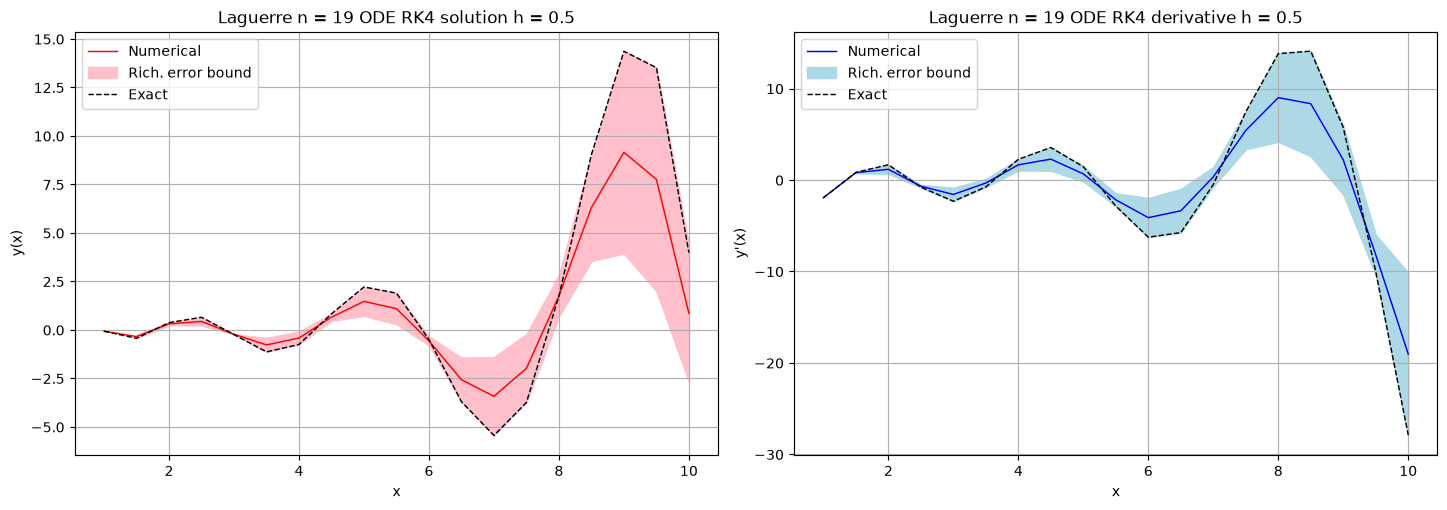

In [10]:
# Plotting
_, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

# y(x)
ax1.set_title(f'Laguerre n = {n} ODE RK4 solution h = {h}')
ax1.plot(x, y, linestyle = 'solid', linewidth = 1.0, label = 'Numerical', color = 'red')
ax1.fill_between(x[1:], y[1:] - erry, y[1:] + erry, color = 'pink', alpha = 1.0, label = 'Rich. error bound')
ax1.plot(x, Ln(x), linestyle = 'dashed', linewidth = 1.0, label = 'Exact', color = 'black')
ax1.grid()
ax1.set_xlabel('x')
ax1.set_ylabel('y(x)')
ax1.legend(loc = 'best')

# y'(x)
ax2.set_title(f'Laguerre n = {n} ODE RK4 derivative h = {h}')
ax2.plot(x, v, linestyle = 'solid', linewidth = 1.0, label = 'Numerical', color = 'blue')
ax2.fill_between(x[1:], v[1:] - errv, v[1:] + errv, color = 'lightblue', alpha = 1.0, label = 'Rich. error bound')
ax2.plot(x, Ln.deriv(m = 1)(x), linestyle = 'dashed', linewidth = 1.0, label = 'Exact', color = 'black')
ax2.grid()
ax2.set_xlabel('x')
ax2.set_ylabel("y'(x)")
ax2.legend(loc = 'best')

plt.tight_layout()
plt.show()

Let's reduce $h$ to $0.1$

In [11]:
h = 0.1 # Reduce h

In [12]:
# Solution and errors
x, y, v = rk4(
    f = f,
    args = (n,),
    ics = (Ln(x_ini), Ln.deriv(m = 1)(x_ini)),
    xrange = (x_ini, x_fin),
    h = h
)

_, y2, v2 = rk4(
    f = f,
    args = (n,),
    ics = (Ln(x_ini), Ln.deriv(m = 1)(x_ini)),
    xrange = (x_ini, x_fin),
    h = h / 2.0
)

_, y4, v4 = rk4(
    f = f,
    args = (n,),
    ics = (Ln(x_ini), Ln.deriv(m = 1)(x_ini)),
    xrange = (x_ini, x_fin),
    h = h / 4.0
)

py = np.log2(abs((y2[2::2] - y[1:]) / (y4[4::4] - y2[2::2])))
pv = np.log2(abs((v2[2::2] - v[1:]) / (v4[4::4] - v2[2::2])))

py, pv # Better

(array([ 4.0762008 ,  4.23338721,  4.54268365,  8.42054322,  2.8519852 ,
         3.57726409,  3.77859286,  3.8898983 ,  3.97325138,  4.05054617,
         4.137615  ,  4.25970372,  4.49492376,  5.4787306 ,  0.25018729,
         3.34768815,  3.65662915,  3.79308179,  3.87871611,  3.94426382,
         4.00224449,  4.06031323,  4.12602023,  4.21127762,  4.34360458,
         4.61918424,  5.9452705 , -0.79089388,  3.24073798,  3.58675307,
         3.73539205,  3.82454144,  3.88857961,  3.94061857,  3.98721717,
         4.03263966,  4.0806614 ,  4.13592068,  4.20597703,  4.30645994,
         4.4793879 ,  4.90036404,  7.54807847,  1.72750135,  3.25327701,
         3.56078732,  3.70400191,  3.79153855,  3.85386332,  3.90311004,
         3.94526566,  3.98385261,  4.02136537,  4.05999754,  4.10218415,
         4.15126935,  4.21273904,  4.29717679,  4.42920455,  4.6849172 ,
         5.50649995,  4.0427991 ,  2.44512673,  3.29191128,  3.55078404,
         3.68325693,  3.76716284,  3.82746388,  3.8

In [13]:
# Errors
erry = abs(2 ** py / (2 ** py - 1.0) * (y2[2::2] - y[1:]))
errv = abs(2 ** pv / (2 ** pv - 1.0) * (v2[2::2] - v[1:]))

erry, errv

(array([4.33606237e-05, 6.76699125e-05, 6.29624846e-05, 2.84808027e-05,
        3.04836635e-05, 1.03296505e-04, 1.79027770e-04, 2.46178881e-04,
        2.94839554e-04, 3.17538343e-04, 3.09761680e-04, 2.70123817e-04,
        2.00252198e-04, 1.04481349e-04, 3.57791630e-05, 1.38239683e-04,
        2.67606535e-04, 3.90379583e-04, 4.97603693e-04, 5.81228140e-04,
        6.34527677e-04, 6.52452791e-04, 6.31876389e-04, 5.71732616e-04,
        4.73051520e-04, 3.38902654e-04, 1.74312635e-04, 6.92376828e-06,
        2.20475160e-04, 4.32492975e-04, 6.42411872e-04, 8.40358538e-04,
        1.01671371e-03, 1.16241001e-03, 1.26927547e-03, 1.33035052e-03,
        1.34016223e-03, 1.29494764e-03, 1.19282049e-03, 1.03387876e-03,
        8.20255213e-04, 5.56132525e-04, 2.50614647e-04, 1.05978100e-04,
        4.73106692e-04, 8.62307317e-04, 1.25656978e-03, 1.64310432e-03,
        2.00885891e-03, 2.34074491e-03, 2.62597808e-03, 2.85243384e-03,
        3.00899680e-03, 3.08589357e-03, 3.07500075e-03, 2.970120

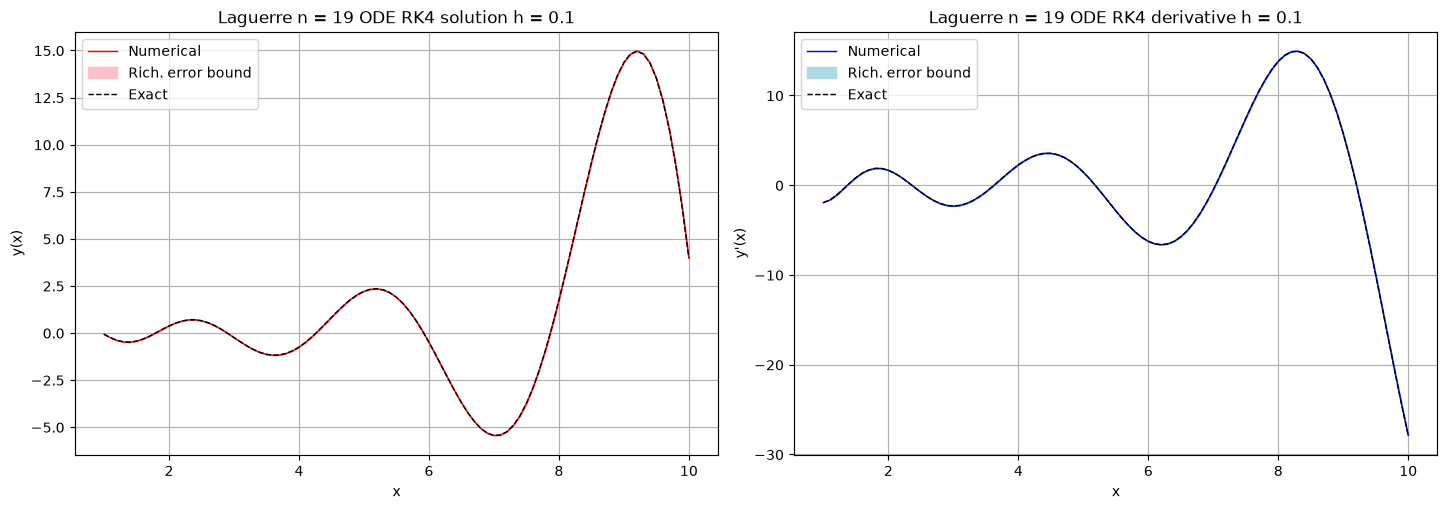

In [14]:
# Plotting
_, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

# y(x)
ax1.set_title(f'Laguerre n = {n} ODE RK4 solution h = {h}')
ax1.plot(x, y, linestyle = 'solid', linewidth = 1.0, label = 'Numerical', color = 'red')
ax1.fill_between(x[1:], y[1:] - erry, y[1:] + erry, color = 'pink', alpha = 1.0, label = 'Rich. error bound')
ax1.plot(x, Ln(x), linestyle = 'dashed', linewidth = 1.0, label = 'Exact', color = 'black')
ax1.grid()
ax1.set_xlabel('x')
ax1.set_ylabel('y(x)')
ax1.legend(loc = 'best')

# y'(x)
ax2.set_title(f'Laguerre n = {n} ODE RK4 derivative h = {h}')
ax2.plot(x, v, linestyle = 'solid', linewidth = 1.0, label = 'Numerical', color = 'blue')
ax2.fill_between(x[1:], v[1:] - errv, v[1:] + errv, color = 'lightblue', alpha = 1.0, label = 'Rich. error bound')
ax2.plot(x, Ln.deriv(m = 1)(x), linestyle = 'dashed', linewidth = 1.0, label = 'Exact', color = 'black')
ax2.grid()
ax2.set_xlabel('x')
ax2.set_ylabel("y'(x)")
ax2.legend(loc = 'best')

plt.tight_layout()
plt.show()